In [ ]:
# 개별 센서 수치(z-score)만 보면 지극히 정상이지만, 
# 두 변수 간의 물리적 관계(양의 상관관계)가 깨진 이상 데이터를 단변량 기준은 놓치고 
# 다변량 기준(마할라노비스 거리)만 잡아낸다는 것을 수치와 산점도로 한눈에 보여주는 예제입니다.

[184.     4.82]


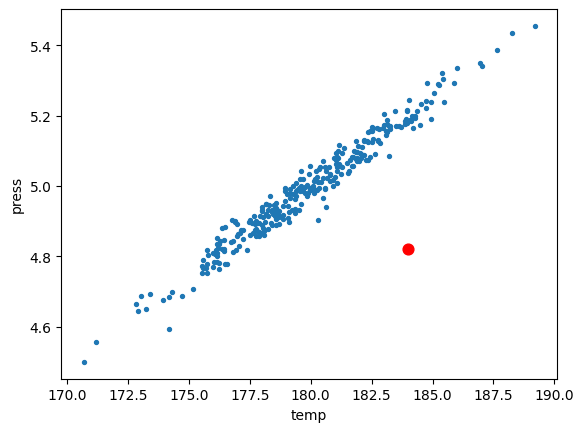

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 임시 데이터 생성
rng = np.random.default_rng(0)
temp = rng.normal(180, 3, 300) # 평균 180, 표준편차 3을 따르는 정상 온도 데이터 300개를 생성

# 온도가 180 을 넘으면 온도가 오름(180:0, 181:5.05, ...)
press = 5 + 0.05 * (temp - 180) 
press += rng.normal(0, 0.03, 300)   # 미세한 공정 노이즈.
X = np.c_[temp, press] # 온도와 압력을 X 에 담는다.(300,2)

# 비정상 데이터 [온도, 압력]
# 공식대로라면 온도가 184일 때 압력은 5 + 0.05 * (184 - 180) = 5.20 근처여야함
# 하지만, 4.82 로 설정하여 맞지 않는 수치가 됨
anomaly = np.array([184, 4.82]) # 정상대로라면 184, 5.20
print(anomaly)

# 온도에 따른 압력(파란색) 과 이상값(빨간색) 에 대한 거리(마할라노비스 거리) 를 측정해 보자
plt.scatter(temp, press, s=8)
plt.scatter(*anomaly, c='r', s=60) # *anomaly == anomaly[0],anomaly[1]
plt.xlabel('temp')
plt.ylabel('press')
plt.show()

In [ ]:
# 정상 데이터의 온도와 압력의 평균과 표준편차를 구함
mu, sd = X.mean(0), X.std(0)
# print(mu)
# print(sd)
print(X.shape)

# X.T로 행과 열을 뒤집어 (2, 300) 형태로 만든 뒤 np.cov()로 2 X 2 공분산 행렬을 계산하고
# np.cov() : 변수 간의 선형적 상관관계 방향과 크기를 파악하는 함수
# 하지만 cov 는 각 col 을 변수로 보기 때문에 X 그대로의 (300,2) 형태로 넣을 수 없다.
# 그래서 T 를 통해 행과 열을 뒤집어(2,300) 형태로 변경 후 np.cov() 사용
cov = np.cov(X.T)
print(cov)
""" 여기서 분산은 한 변수의 퍼짐 정도이고, 공분산은 두 변수가 공통으로 퍼지는 방향성(각도, 방향)
         온도        압력
온도 [9.35479322, 0.47152565] # 온도의 분산, 온도/압력의 공분산
압력 [0.47152565, 0.02462433] # 온도/압력의 공분산, 압력의 분산
"""

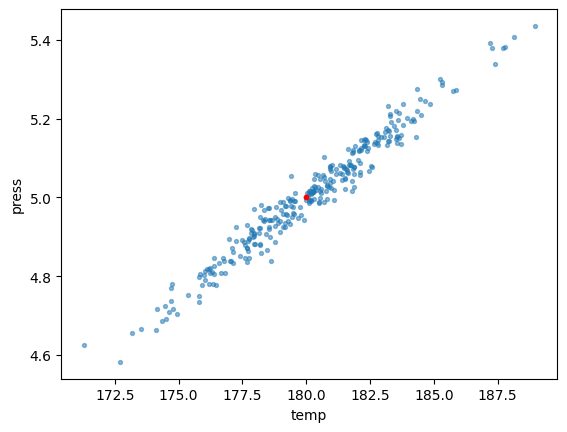

In [ ]:
# 위에서 구한 공분산 행렬을 이용하여 비슷한 모양을 만들 수 있다.
center = np.array([180.0,5.0]) #  중심
# 중심점과 공분산행렬을 따르는 무작위 샘플 추출
samples = rng.multivariate_normal(center, cov, size=300)

plt.scatter(samples[:, 0], samples[:, 1], s=8, alpha=0.5)
plt.scatter(*center, c='r', s=10) # *anomaly == anomaly[0],anomaly[1]
plt.xlabel('temp')
plt.ylabel('press')
plt.show()

In [ ]:
# cov로 구한 공분산 행렬을 데이터가 대각선으로는 길게, 위아래로 좁게 모여 있음
# 이 경우 대각선 방향의 변화는 작게 반영하고, 위아래 방향은 크게 반영해야 한다.
# 그래서 역행렬을 곱해 넓게 퍼진 방향의 영향력은 줄이고, 좁게 모인 방향의 민감도는 키움
# 이렇게 이상치를 잘 잡아낼 수 있도록 거리 계산의 가중치를 보정
inv = np.linalg.inv(cov)
print(inv)

In [23]:
# 중심에서 얼마나 떨어졌는지는 마할라노비스 거리를 내야 한다.
# 행렬곱?
"""
[a1,a2] @ [b1,c1] = [(a1*b1)+(a2*b2), (a1*c1)+(a2*c2)]
          [b2,c2]
[a1,a2] @ b1 = [(a1*b1)+(a2*b2)]
          b2
"""
def maha(p): # 임의의 데이터 포인트 p
    # 중심(mu)과의 차이 @ 역행렬 @ 중심(mu)과의 차이
    return np.sqrt((p - mu) @ inv @ (p - mu))
# maha(X[0])


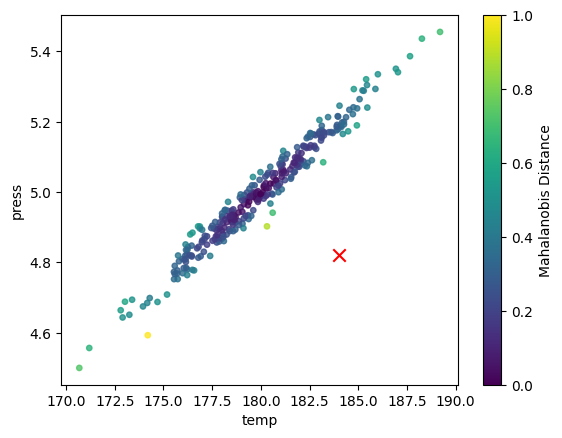

In [ ]:

# 각각의 거리를 재서...
dists = np.array([maha(row) for row in X])
# 중앙에서 부터 얼마나 떨어져 있는지 확인해 보자
plt.scatter(X[:, 0], X[:, 1], c=dists, cmap="viridis", s=15, alpha=0.8)
plt.scatter(*anomaly, c="red", s=80, marker="x")
plt.colorbar(label="Mahalanobis Distance")
plt.xlabel("temp")
plt.ylabel("press")
plt.show()


In [26]:
# 이제는 이상치 데이터를 가지고 거리를 재 보자
# 중심으로부터의 차이를 표준편차와 비교해 보면 그리 크게 벗어난 것으로 보이지 않는다.
print('항목별 z-score :', ((anomaly - mu) / sd).round(2))          # 모두 ±3 이내

# 그런데 마할라노비스 거리로 재면 차이가 커짐
print('마할라노비스 거리 :', maha(anomaly).round(2))

# 정상데이터 중 마할라노비스 거리로 최대로 먼 것은?
print('정상 데이터 최대 :', max(maha(r) for r in X).round(2))


항목별 z-score : [ 1.35 -1.11]
마할라노비스 거리 : 13.09
정상 데이터 최대 : 4.33
